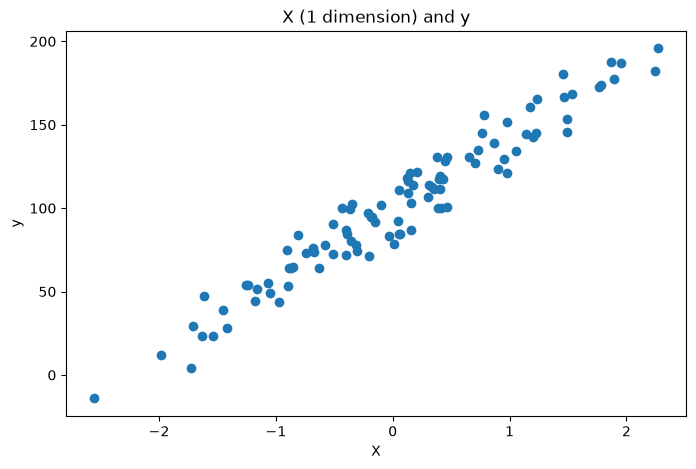

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from functools import partial
from multiprocessing import Pool
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression

X, y, coef = make_regression(
    n_samples=100,
    n_features=1,
    n_informative=1,
    noise=10,
    coef=True,
    random_state=0,
    bias=100.0
)

X_flat = X.reshape(1, -1)[0]

plt.figure(figsize=(8, 5))
plt.scatter(X_flat, y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("X (1 dimension) and y")
plt.show()


In [2]:
def compute_mse(coefs, X, y):
    a, b = coefs
    X_1d = X.reshape(-1)
    y_preds = a * X_1d + b
    mse = float(np.mean((y_preds - y) ** 2))
    return mse

print("MSE for a=1, b=2:", compute_mse([1, 2], X, y))


MSE for a=1, b=2: 11808.867339751561


In [ ]:
aa, bb = np.mgrid[-200:200:0.5, -200:200:0.5]
grid = np.c_[aa.ravel(), bb.ravel()]
print("Grid shape:", grid.shape)  

mse_partial = partial(compute_mse, X=X_flat, y=y)

with Pool() as pool:
    losses = pool.map(mse_partial, grid)


Grid shape: (640000, 2)


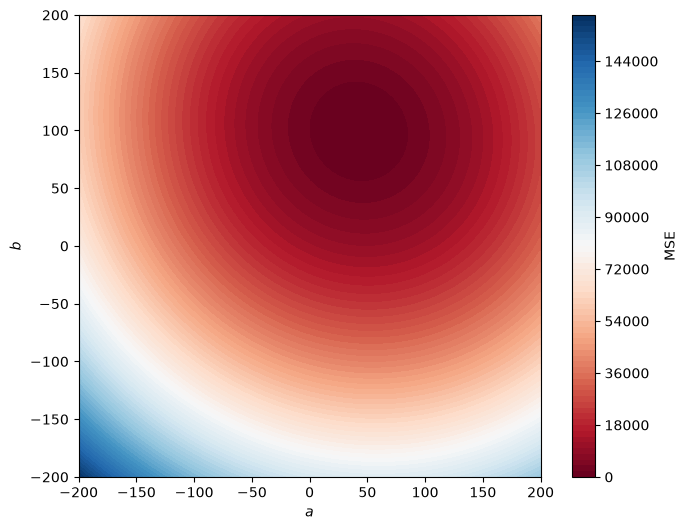

In [5]:
losses_reshaped = np.array(losses).reshape(aa.shape)

f, ax = plt.subplots(figsize=(8, 6))
contour = ax.contourf(
    aa, bb, losses_reshaped, 100, cmap="RdBu", vmin=0, vmax=160000
)
ax_c = f.colorbar(contour)
ax_c.set_label("MSE")
ax.set(
    aspect="equal",
    xlim=(-200, 200),
    ylim=(-200, 200),
    xlabel="$a$",
    ylabel="$b$"
)
plt.show()




Best Grid Search -> a: 42.5, b: 99.0, MSE: 114.2232


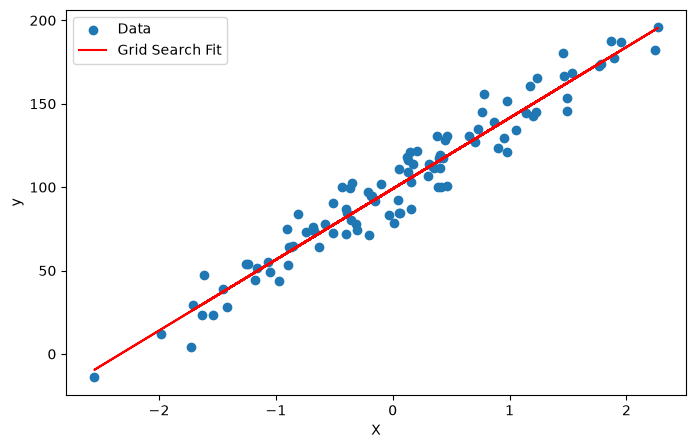

In [6]:
best_idx = np.argmin(losses)
best_a, best_b = grid[best_idx]
print(f"Best Grid Search -> a: {best_a}, b: {best_b}, MSE: {losses[best_idx]:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_flat, y, label="Data")
plt.plot(X_flat, best_a * X_flat + best_b, color="red", label="Grid Search Fit")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [7]:
def gradient_descent(X, y, learning_rate=0.1, nbr_iterations=100, init_a=-150.0, init_b=-150.0):
    X_1d = X.reshape(-1)
    n = len(y)
    a, b = init_a, init_b
    history = np.zeros((nbr_iterations, 2))

    for i in range(nbr_iterations):
        history[i] = [a, b]
        y_pred = a * X_1d + b
        error = y_pred - y
        grad_a = (2 / n) * np.dot(error, X_1d)
        grad_b = (2 / n) * np.sum(error)
        a -= learning_rate * grad_a
        b -= learning_rate * grad_b

    return a, b, history

gd_a, gd_b, history = gradient_descent(X_flat, y, learning_rate=0.1, nbr_iterations=100)
print(f"Gradient Descent -> a: {gd_a:.4f}, b: {gd_b:.4f}, MSE: {compute_mse([gd_a, gd_b], X_flat, y):.4f}")


Gradient Descent -> a: 42.6194, b: 99.1858, MSE: 114.1715


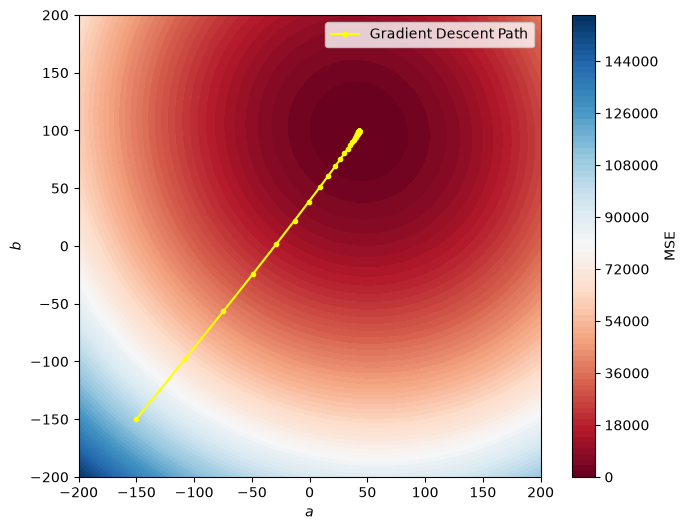

In [8]:
f, ax = plt.subplots(figsize=(8, 6))
contour = ax.contourf(
    aa, bb, losses_reshaped, 100, cmap="RdBu", vmin=0, vmax=160000
)
ax_c = f.colorbar(contour)
ax_c.set_label("MSE")

ax.plot(history[:, 0], history[:, 1], "o-", color="yellow", markersize=3, label="Gradient Descent Path")
ax.set(
    aspect="equal",
    xlim=(-200, 200),
    ylim=(-200, 200),
    xlabel="$a$",
    ylabel="$b$"
)
ax.legend()
plt.show()


In [9]:
sk_model = LinearRegression()
sk_model.fit(X, y)
sk_a = sk_model.coef_[0]
sk_b = sk_model.intercept_
sk_mse = compute_mse([sk_a, sk_b], X_flat, y)

print(f"Scikit-learn     -> a: {sk_a:.4f}, b: {sk_b:.4f}, MSE: {sk_mse:.4f}")


Scikit-learn     -> a: 42.6194, b: 99.1858, MSE: 114.1715
